# Predicción de compra en sesiones de e-commerce
**SIS-352 · Trabajo final · Metodología CRISP-ML(Q)**

Dataset: *Online Shoppers Purchasing Intention* (Kaggle). Cada fila es una sesión de navegación en una tienda online; la columna `Revenue` indica si la sesión terminó en compra.

Este notebook cubre las fases 1 a 4 de CRISP-ML(Q). Lo que se decide aquí (pipeline, hiperparámetros y umbral) es lo que luego usa el servicio de IA para reentrenar de forma automática.

## Fase 1 · Business & Data Understanding

**Objetivo de negocio:** detectar a tiempo las sesiones con intención de compra para que la tienda actúe (cupón, chat de ayuda, envío gratis) y no pierda la venta.

**Errores y su costo:**
- **Falso negativo (FN):** la sesión iba a comprar y el modelo dijo que no → no se actúa y se puede perder la venta. **Es el error caro.**
- **Falso positivo (FP):** el modelo dijo compra y no compró → se gastó un cupón o un mensaje. Costo bajo.

**Métrica y criterio de éxito:**
- **Recall(compra) ≥ 70 %** en el conjunto de prueba (requisito).
- **F2** como métrica principal para elegir modelo (da más peso al Recall que a la Precision).
- **ROC-AUC** como apoyo para ver la capacidad de separar clases.

**Tipo de problema:** clasificación binaria supervisada.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
import joblib

RANDOM_STATE = 42
os.makedirs('../docs/capturas', exist_ok=True)
sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('../data/online_shoppers_intention.csv')
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [5]:
print('Valores nulos por columna:')
print(df.isnull().sum().sum(), 'nulos en total')
print('Filas duplicadas:', df.duplicated().sum())

Valores nulos por columna:
0 nulos en total
Filas duplicadas: 125


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


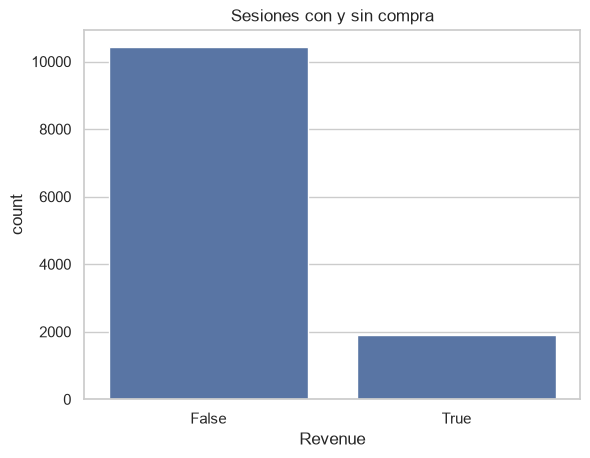

In [6]:
print(df['Revenue'].value_counts())
print(df['Revenue'].value_counts(normalize=True).round(3))

sns.countplot(x='Revenue', data=df)
plt.title('Sesiones con y sin compra')
plt.savefig('../docs/capturas/01_balance_clases.png', dpi=120, bbox_inches='tight')
plt.show()

Las clases están **desbalanceadas**: solo ~15,5 % de las sesiones terminan en compra. Por eso no se usa Accuracy (un modelo que diga siempre "no compra" tendría ~85 %), y se usan Recall y F2.

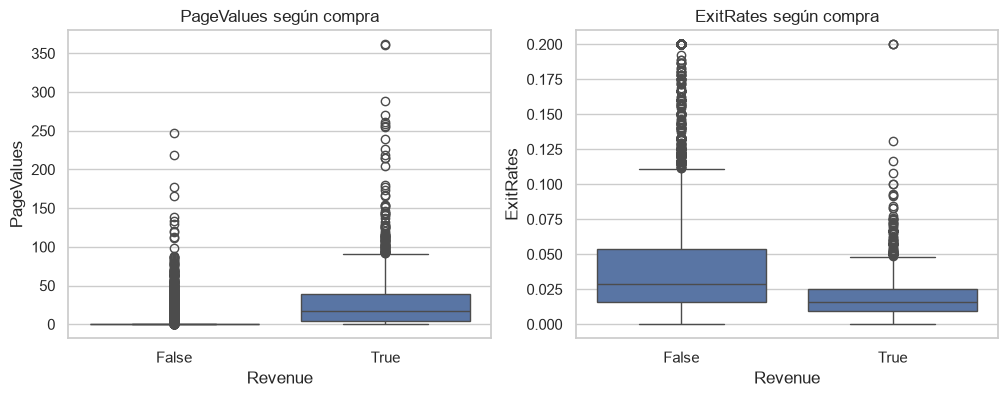

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='Revenue', y='PageValues', data=df, ax=axes[0])
axes[0].set_title('PageValues según compra')
sns.boxplot(x='Revenue', y='ExitRates', data=df, ax=axes[1])
axes[1].set_title('ExitRates según compra')
plt.savefig('../docs/capturas/02_pagevalues_exitrates.png', dpi=120, bbox_inches='tight')
plt.show()

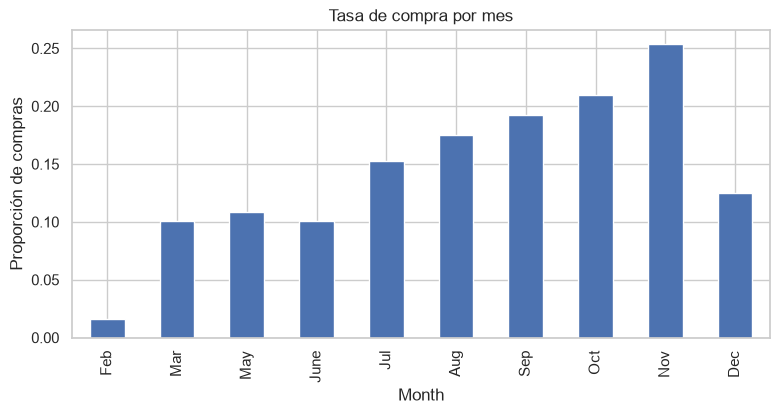

VisitorType
New_Visitor          0.249
Other                0.188
Returning_Visitor    0.139
Name: Revenue, dtype: float64


In [8]:
orden_meses = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
tasa_mes = df.groupby('Month')['Revenue'].mean().reindex(orden_meses)
tasa_mes.plot(kind='bar', figsize=(9, 4), title='Tasa de compra por mes')
plt.ylabel('Proporción de compras')
plt.savefig('../docs/capturas/03_tasa_mes.png', dpi=120, bbox_inches='tight')
plt.show()

print(df.groupby('VisitorType')['Revenue'].mean().round(3))

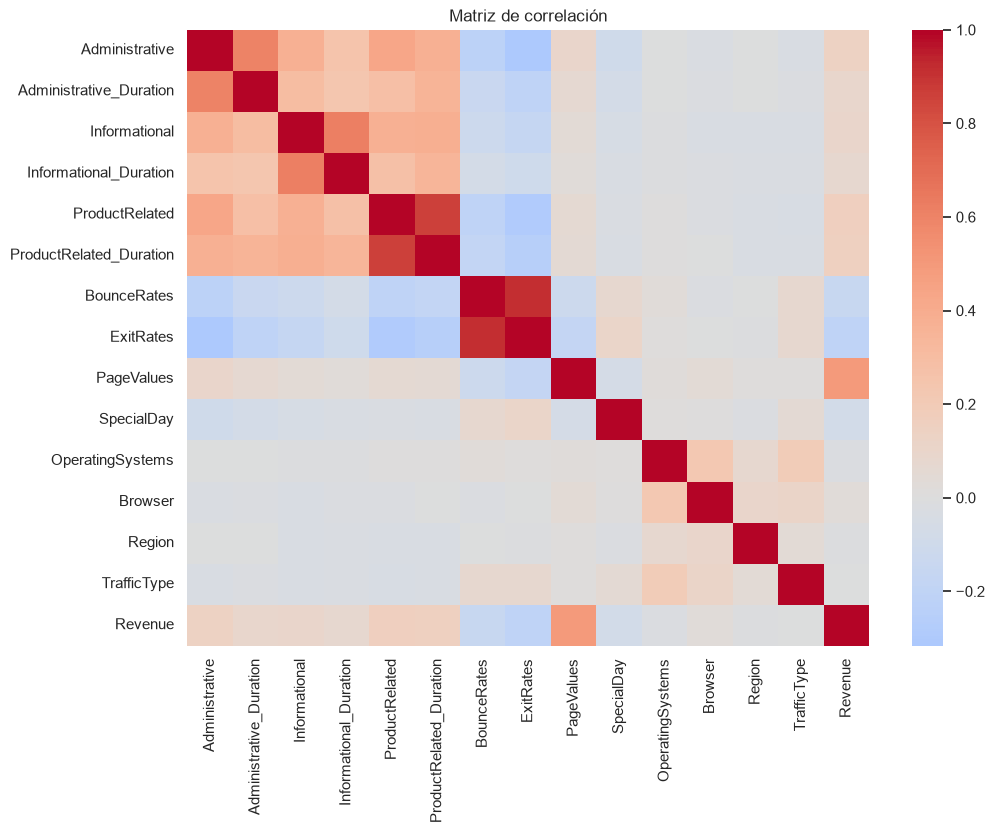

PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
Browser                    0.024
TrafficType               -0.005
Region                    -0.012
OperatingSystems          -0.015
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
dtype: float64


In [9]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes(include='number').assign(Revenue=df['Revenue'].astype(int)).corr(),
            cmap='coolwarm', center=0, annot=False)
plt.title('Matriz de correlación')
plt.savefig('../docs/capturas/04_correlacion.png', dpi=120, bbox_inches='tight')
plt.show()

print(df.select_dtypes(include='number').corrwith(df['Revenue'].astype(int)).sort_values(ascending=False).round(3))

**Hallazgos de la fase 1**
- 12 330 sesiones, 17 variables de entrada y 1 objetivo. **No hay nulos**; hay **125 duplicados**.
- `PageValues` es la variable más relacionada con la compra; `ExitRates` y `BounceRates` se relacionan en sentido contrario.
- Noviembre tiene la tasa de compra más alta; los visitantes nuevos compran proporcionalmente más que los recurrentes.
- Una regla simple como "PageValues > 0" no alcanza: el 19 % de las compras tiene PageValues = 0 y varias variables interactúan, así que se justifica usar ML.
- **Riesgos:** desbalance de clases; datos de un solo año; variables `Region`, `Browser`, `OperatingSystems` y `TrafficType` vienen como códigos sin descripción. Los datos son anónimos (sin información personal).

## Fase 2 · Data Engineering

1. Eliminar duplicados.
2. Separar variables de entrada (`X`) y objetivo (`y`).
3. Dividir en entrenamiento y prueba (80/20, estratificado) **antes** de ajustar cualquier transformación, para evitar *data leakage*.
4. Armar un **pipeline** de preprocesamiento:
   - Numéricas: imputación con la mediana (hoy no hay nulos, pero el servicio puede recibir datos nuevos con faltantes).
   - Categóricas (`Month`, `VisitorType`): imputación con la moda + One-Hot Encoding.
   - `Weekend` ya es booleana y se pasa como 0/1.
   - No se escala porque los modelos son de árboles y no lo necesitan.

In [10]:
df = df.drop_duplicates()
print('Filas después de quitar duplicados:', df.shape[0])

df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

X = df.drop(columns='Revenue')
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Proporción de compras  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Filas después de quitar duplicados: 12205
Train: (9764, 17)  Test: (2441, 17)
Proporción de compras  train: 0.156  test: 0.156


In [11]:
columnas_categoricas = ['Month', 'VisitorType']
columnas_numericas = [c for c in X.columns if c not in columnas_categoricas]

preprocesador = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), columnas_numericas),
    ('cat', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), columnas_categoricas)
])

print('Numéricas:', columnas_numericas)
print('Categóricas:', columnas_categoricas)

Numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
Categóricas: ['Month', 'VisitorType']


## Fase 3 · ML Model Engineering

**Hipótesis:** XGBoost supera a Random Forest en F2 porque corrige los errores de forma secuencial (boosting) y maneja bien el desbalance con `scale_pos_weight`.

- **Random Forest** (baseline) con `class_weight='balanced'`.
- **XGBoost** con `scale_pos_weight` = negativos / positivos.
- Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento.

In [12]:
f2 = make_scorer(fbeta_score, beta=2)
metricas_cv = {'recall': 'recall', 'precision': 'precision', 'f2': f2, 'roc_auc': 'roc_auc'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

peso_positivos = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight = %.2f' % peso_positivos)

modelos = {
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                             scale_pos_weight=peso_positivos, eval_metric='logloss',
                             random_state=RANDOM_STATE, n_jobs=-1)
}

resultados = []
for nombre, modelo in modelos.items():
    pipe = Pipeline([('prep', preprocesador), ('modelo', modelo)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=1)
    resultados.append({'modelo': nombre, **{m: r['test_' + m].mean() for m in metricas_cv}})

pd.DataFrame(resultados).set_index('modelo').round(3)

scale_pos_weight = 5.40


,recall,precision,f2,roc_auc
modelo,,,,
Random Forest,0.739,0.640,0.717,0.930
XGBoost,0.776,0.579,0.726,0.925


Con parámetros iniciales los dos modelos ya superan el 70 % de Recall en validación cruzada. XGBoost tiene más Recall y Random Forest más Precision; en F2 están muy cerca. Para decidir, se optimizan los hiperparámetros de ambos con **RandomizedSearchCV** (15 combinaciones por modelo, F2 como métrica).

In [13]:
busquedas = {
    'Random Forest': (
        Pipeline([('prep', preprocesador),
                  ('modelo', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))]),
        {'modelo__n_estimators': [200, 300, 500],
         'modelo__max_depth': [6, 8, 10, 14, None],
         'modelo__min_samples_leaf': [1, 3, 5, 10],
         'modelo__max_features': ['sqrt', 0.5]}
    ),
    'XGBoost': (
        Pipeline([('prep', preprocesador),
                  ('modelo', XGBClassifier(scale_pos_weight=peso_positivos, eval_metric='logloss',
                                           random_state=RANDOM_STATE, n_jobs=-1))]),
        {'modelo__n_estimators': [200, 300, 500],
         'modelo__max_depth': [3, 4, 5, 6],
         'modelo__learning_rate': [0.03, 0.05, 0.1],
         'modelo__subsample': [0.8, 1.0],
         'modelo__colsample_bytree': [0.7, 0.8, 1.0],
         'modelo__min_child_weight': [1, 3, 5]}
    )
}

mejores = {}
for nombre, (pipe, grilla) in busquedas.items():
    busqueda = RandomizedSearchCV(pipe, grilla, n_iter=15, scoring=f2, cv=cv,
                                  random_state=RANDOM_STATE, n_jobs=1)
    busqueda.fit(X_train, y_train)
    mejores[nombre] = busqueda
    print(nombre, '-> F2 CV = %.3f' % busqueda.best_score_)
    print('   ', busqueda.best_params_)

Random Forest -> F2 CV = 0.756
    {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.5, 'modelo__max_depth': 6}


XGBoost -> F2 CV = 0.754
    {'modelo__subsample': 1.0, 'modelo__n_estimators': 300, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.03, 'modelo__colsample_bytree': 0.8}


In [14]:
nombre_ganador = max(mejores, key=lambda n: mejores[n].best_score_)
modelo_final = mejores[nombre_ganador].best_estimator_
hiperparametros = {k.replace('modelo__', ''): v for k, v in mejores[nombre_ganador].best_params_.items()}
print('Modelo elegido:', nombre_ganador)
print(hiperparametros)

Modelo elegido: Random Forest
{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 6}


**Conclusión de la fase 3:** tras la optimización los dos modelos quedan prácticamente empatados en F2 (diferencia de milésimas). Se elige el de mayor F2 en validación cruzada. Si el ganador es Random Forest, la hipótesis inicial (XGBoost mejor) **se rechaza**: el boosting no aportó una mejora real en este dataset, y Random Forest es además más simple de explicar y menos sensible a los hiperparámetros.

## Fase 4 · Evaluation & QA

1. **Umbral de decisión:** el modelo devuelve una probabilidad; por defecto se corta en 0,5. Se busca el umbral que maximiza F2 cumpliendo Recall ≥ 70 %, usando las predicciones de validación cruzada del **entrenamiento** (no el test, para no hacer trampa).
2. **Test ciego:** se evalúa una sola vez en el 20 % reservado.
3. **Explicabilidad:** importancia de variables.
4. **Robustez:** se agrega ruido a los datos de prueba y se mide cuánto cae el Recall.
5. **Sesgos:** se compara el Recall entre grupos (tipo de visitante, fin de semana).

Umbral elegido: 0.39


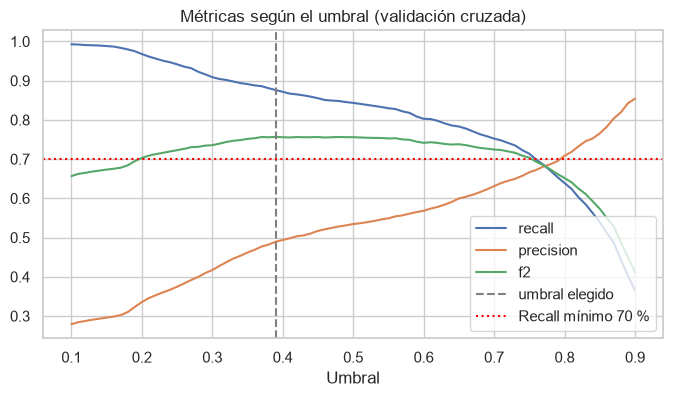

In [15]:
prob_cv = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

umbrales = np.arange(0.10, 0.91, 0.01)
tabla_umbral = pd.DataFrame({
    'umbral': umbrales,
    'recall': [recall_score(y_train, prob_cv >= u) for u in umbrales],
    'precision': [precision_score(y_train, prob_cv >= u, zero_division=0) for u in umbrales],
    'f2': [fbeta_score(y_train, prob_cv >= u, beta=2) for u in umbrales]
})
candidatos = tabla_umbral[tabla_umbral['recall'] >= 0.70]
umbral = float(round(candidatos.loc[candidatos['f2'].idxmax(), 'umbral'], 2))
print('Umbral elegido:', umbral)

plt.figure(figsize=(8, 4))
for m in ['recall', 'precision', 'f2']:
    plt.plot(tabla_umbral['umbral'], tabla_umbral[m], label=m)
plt.axvline(umbral, color='gray', linestyle='--', label='umbral elegido')
plt.axhline(0.70, color='red', linestyle=':', label='Recall mínimo 70 %')
plt.xlabel('Umbral'); plt.legend(); plt.title('Métricas según el umbral (validación cruzada)')
plt.savefig('../docs/capturas/05_umbral.png', dpi=120, bbox_inches='tight')
plt.show()

In [16]:
modelo_final.fit(X_train, y_train)
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= umbral).astype(int)

metricas_test = {
    'recall': recall_score(y_test, pred_test),
    'precision': precision_score(y_test, pred_test),
    'f1': f1_score(y_test, pred_test),
    'f2': fbeta_score(y_test, pred_test, beta=2),
    'roc_auc': roc_auc_score(y_test, prob_test)
}
for k, v in metricas_test.items():
    print('%-10s %.3f' % (k, v))
print()
print(classification_report(y_test, pred_test, target_names=['No compra', 'Compra']))
print('¿Cumple Recall >= 70 %?', 'SÍ' if metricas_test['recall'] >= 0.70 else 'NO')

recall     0.895
precision  0.492
f1         0.635
f2         0.769
roc_auc    0.935

              precision    recall  f1-score   support

   No compra       0.98      0.83      0.90      2059
      Compra       0.49      0.90      0.64       382

    accuracy                           0.84      2441
   macro avg       0.73      0.86      0.77      2441
weighted avg       0.90      0.84      0.86      2441

¿Cumple Recall >= 70 %? SÍ


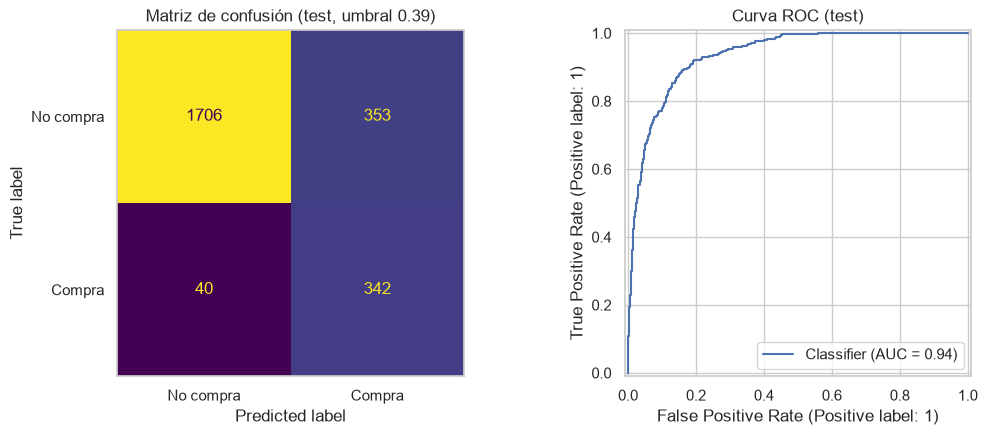

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=['No compra', 'Compra']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de confusión (test, umbral %.2f)' % umbral)
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, prob_test, ax=axes[1])
axes[1].set_title('Curva ROC (test)')
plt.savefig('../docs/capturas/06_confusion_roc.png', dpi=120, bbox_inches='tight')
plt.show()

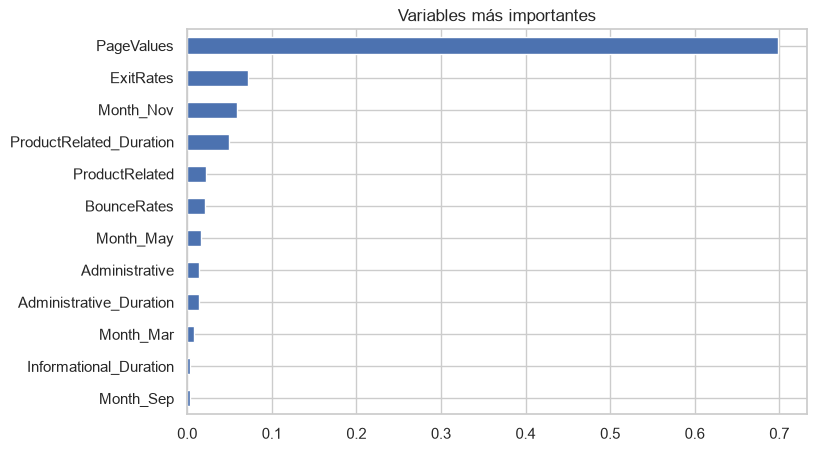

PageValues                 0.698
ExitRates                  0.071
Month_Nov                  0.059
ProductRelated_Duration    0.050
ProductRelated             0.023
BounceRates                0.021
Month_May                  0.016
Administrative             0.014
Administrative_Duration    0.014
Month_Mar                  0.008
dtype: float64

In [18]:
nombres = modelo_final.named_steps['prep'].get_feature_names_out()
nombres = [n.split('__')[1] for n in nombres]
importancia = pd.Series(modelo_final.named_steps['modelo'].feature_importances_, index=nombres).sort_values(ascending=False)

importancia.head(12).sort_values().plot(kind='barh', figsize=(8, 5), title='Variables más importantes')
plt.savefig('../docs/capturas/07_importancia.png', dpi=120, bbox_inches='tight')
plt.show()
importancia.head(10).round(3)

In [19]:
# Robustez: ruido gaussiano del 5 % de la desviación estándar en las variables numéricas continuas
continuas = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration',
             'BounceRates', 'ExitRates', 'PageValues']
rng = np.random.default_rng(RANDOM_STATE)
X_ruido = X_test.copy()
for c in continuas:
    X_ruido[c] = (X_ruido[c] + rng.normal(0, 0.05 * X_test[c].std(), len(X_ruido))).clip(lower=0)

recall_ruido = recall_score(y_test, modelo_final.predict_proba(X_ruido)[:, 1] >= umbral)
print('Recall original: %.3f   Recall con ruido: %.3f   Variación: %+.3f'
      % (metricas_test['recall'], recall_ruido, recall_ruido - metricas_test['recall']))
print('¿Sigue cumpliendo Recall >= 70 % con ruido?', 'SÍ' if recall_ruido >= 0.70 else 'NO')

Recall original: 0.895   Recall con ruido: 0.942   Variación: +0.047
¿Sigue cumpliendo Recall >= 70 % con ruido? SÍ


In [20]:
# Sesgos: Recall por grupo
evaluacion = X_test.assign(real=y_test.values, pred=pred_test)
for grupo in ['VisitorType', 'Weekend']:
    print(evaluacion[evaluacion['real'] == 1].groupby(grupo).apply(
        lambda g: pd.Series({'compras': len(g), 'recall': (g['pred'] == 1).mean()}), include_groups=False).round(3))
    print()

                   compras  recall
VisitorType                       
New_Visitor           97.0   0.845
Returning_Visitor    285.0   0.912

         compras  recall
Weekend                 
0          282.0   0.887
1          100.0   0.920



**Conclusión de la fase 4 (go / no-go: GO)**
- En el test ciego el modelo **cumple el requisito**: Recall(compra) muy por encima del 70 %, con F2 y ROC-AUC altos.
- El precio es una Precision cercana al 50 %: de cada 2 sesiones marcadas como compra, una no compra. Para el negocio es aceptable porque un FP solo cuesta un cupón o un mensaje.
- `PageValues` domina la decisión, seguida de `ExitRates` y el mes de noviembre, lo que coincide con el EDA.
- Con ruido el Recall se mantiene sobre el 70 %: el modelo es estable ante pequeñas variaciones.
- El Recall es parecido entre visitantes nuevos y recurrentes y entre días de semana y fin de semana; no se observa un sesgo fuerte.

## Resultado para el despliegue (Fase 5)

Se guardan:
- `config_modelo.json`: algoritmo, hiperparámetros, umbral y métricas. **El servicio de IA lo lee para reentrenar** con los datos de la base de datos usando exactamente esta configuración.
- `modelo_notebook.joblib`: el pipeline completo entrenado, como referencia.

In [21]:
config = {
    'algoritmo': nombre_ganador,
    'hiperparametros': hiperparametros,
    'balanceo': 'class_weight=balanced' if nombre_ganador == 'Random Forest' else 'scale_pos_weight = negativos/positivos (se recalcula al reentrenar)',
    'umbral': umbral,
    'columnas_numericas': columnas_numericas,
    'columnas_categoricas': columnas_categoricas,
    'random_state': RANDOM_STATE,
    'metricas_test': {k: round(float(v), 4) for k, v in metricas_test.items()},
    'filas_entrenamiento': int(len(X_train)),
    'filas_test': int(len(X_test))
}
with open('../api/config_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False, default=str)
joblib.dump(modelo_final, '../api/models/modelo_notebook.joblib')
print(json.dumps(config, indent=2, ensure_ascii=False, default=str))

{
  "algoritmo": "Random Forest",
  "hiperparametros": {
    "n_estimators": 200,
    "min_samples_leaf": 5,
    "max_features": 0.5,
    "max_depth": 6
  },
  "balanceo": "class_weight=balanced",
  "umbral": 0.39,
  "columnas_numericas": [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "Weekend"
  ],
  "columnas_categoricas": [
    "Month",
    "VisitorType"
  ],
  "random_state": 42,
  "metricas_test": {
    "recall": 0.8953,
    "precision": 0.4921,
    "f1": 0.6351,
    "f2": 0.7692,
    "roc_auc": 0.9354
  },
  "filas_entrenamiento": 9764,
  "filas_test": 2441
}


## Fases 5 y 6 (en el servicio)

- **Deployment:** servicio FastAPI + PostgreSQL. Endpoints `/predict`, `/predictions`, `/metrics`, `/retrain` y `/training-data`, documentados con Swagger, y una aplicación web que los consume.
- **Monitoring & Maintenance:** cada predicción se guarda en la base de datos; cuando llegan datos nuevos etiquetados se cargan con `/training-data` y se llama a `/retrain`. El nuevo modelo se registra con sus métricas y solo se activa si mantiene Recall ≥ 70 %.